# Proyecto EVA · Notebook 1 de 2 — Preparación del dataset

**¿Para qué sirve este notebook?** Toma las fotos "crudas" tal como llegan (WhatsApp, capturas, fotos con manos y fondo, distintos tamaños y colores) y las deja **limpias, ordenadas y listas para entrenar**. No entrena ningún modelo: eso se hace en el **Notebook 2**, que solo lee lo que este notebook produce.

**¿Por qué separarlo?** Cuando lleguen más fotos (por ejemplo, más del microscopio azul) solo hay que volver a ejecutar este notebook. El entrenamiento no se toca, y el **test congelado no cambia** aunque el dataset crezca.

### Qué hace, paso a paso

| Paso | Qué pasa | ¿Necesita tu intervención? |
|---|---|---|
| 0 | Configuración | Revisar carpetas y umbrales |
| 1 | Inventario: lista las fotos y arma la planilla maestra (`manifiesto.csv`) | No |
| 2 | Medición automática: detecta el campo del microscopio, el color, el tamaño y alertas de calidad | No |
| 3 | **Revisión visual y etiquetado** | **Sí (manual)** |
| 4 | Detección de duplicados y armado de **grupos** (fotos que van siempre juntas) | No |
| 5 | Decide qué fotos se usan y asigna **dev / test congelado** | No |
| 6 | Exporta las imágenes recortadas y anónimas + la planilla final | No |
| 7 | Resumen y chequeos antes de entrenar | Leer las advertencias |

### Cómo trabajar con él
1. Pon todas las fotos crudas en la carpeta `fotos_crudas/` (junto a este notebook y a `eva_utils.py`).
2. Ejecuta los pasos 0 al 2. Se crea `dataset_eva/manifiesto.csv`.
3. Abre ese CSV (Excel o Google Sheets), completa las columnas manuales (Paso 3) y guárdalo.
4. **Vuelve a ejecutar desde el Paso 1**: el notebook respeta lo que escribiste, recalcula lo automático y termina el proceso.

### Mini glosario
- **Campo:** el círculo luminoso que se ve por el microscopio. Es lo único que nos interesa de cada foto.
- **Manifiesto:** la planilla maestra, con una fila por foto.
- **Nivel (etiqueta):** 0 = sin patrón de helecho · 1 = patrón parcial o dudoso · 2 = patrón claro.
- **Grupo:** conjunto de fotos que probablemente vienen de la misma muestra o sesión. Todas las fotos de un grupo van al mismo lado (entrenamiento o test), para que el modelo no "copie".
- **Test congelado:** fotos que se apartan para siempre y solo se usan para el examen final.

## Paso 0 · Configuración — *definir carpetas y umbrales en un solo lugar*

> **¿Qué hace?** Importa las librerías y fija los parámetros. Todo lo ajustable está aquí.
> **¿Qué tienes que hacer?** Verificar que `RAW_DIR` apunte a la carpeta con tus fotos. El resto puede quedar igual en una primera corrida.

In [1]:
from google.colab import drive
import os, sys

drive.mount('/content/drive')
CARPETA = "/content/drive/MyDrive/Proyecto EVA/files"      # debe coincidir con el nombre de tu carpeta en Drive
os.chdir(CARPETA)
sys.path.insert(0, CARPETA)

print("Carpeta de trabajo:", os.getcwd())
print("Contenido:", os.listdir("."))
print("Fotos encontradas:", len(os.listdir("fotos_crudas")))

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/Proyecto EVA/files
Contenido: ['fotos_crudas', '__pycache__', 'dataset_eva', 'EVA_02_Entrenamiento_Evaluacion.ipynb', 'eva_utils.py', 'EVA_01_Preparacion_Dataset.ipynb']
Fotos encontradas: 24


In [2]:
# Ejecutar solo la primera vez (quita el "#"):
%pip install -q opencv-python-headless pillow-heif pandas matplotlib numpy

In [3]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from eva_utils import (VALID_EXT, abrir, detectar_campo, recortar_campo, color_dominante,
                       descriptor_estructura, md5_archivo, construir_grupos, hash_pct, fecha_whatsapp)

warnings.filterwarnings("ignore")

# ===== Carpetas =====
RAW_DIR  = "fotos_crudas"                 # fotos tal como llegaron (NO se modifican nunca)
OUT_DIR  = Path("dataset_eva")            # aquí se guarda todo lo generado
PROC_DIR = OUT_DIR / "imgs"               # imágenes recortadas y anónimas
MANIFEST = OUT_DIR / "manifiesto.csv"     # planilla maestra (con nombres originales; mantener en privado)
OUT_DIR.mkdir(exist_ok=True)
PROC_DIR.mkdir(exist_ok=True)

# ===== Criterios y parámetros =====
MAX_LADO_MASTER  = 1024    # las imágenes exportadas se reducen a este tamaño máximo (nunca se amplían)
MIN_LADO_PX      = 500     # campo más pequeño que esto (en px) -> alerta 'resolucion_baja' y se excluye por defecto
VENTANA_LOTE_MIN = 5       # fotos enviadas con menos de N minutos de diferencia = mismo "lote"
AGRUPAR_POR_LOTE = True    # considerar que un lote de envío es una misma sesión/muestra (para evitar fuga de datos)
UMBRAL_DUP       = 0.85    # similitud (0-1) desde la cual dos fotos se consideran casi idénticas
TEST_PCT         = 20      # % aproximado de grupos que se aparta como test congelado
SPLIT_SAL        = "eva-v1"  # NO cambiar una vez iniciado el proyecto: define qué grupos caen en test
FORZAR_REEXPORTAR = False  # True = vuelve a generar todas las imágenes procesadas

# Según lo que sabemos: microscopio v1 (proveedor externo) = luz verde/amarilla; microscopio propio = luz azul.
DISPOSITIVO_POR_COLOR = {"azul": "EVA_propio", "verde": "v1_proveedor", "amarillo": "v1_proveedor"}

## Paso 1 · Inventario de fotos y planilla maestra — *listar todas las fotos y darles un identificador anónimo*

> **¿Qué hace?** Recorre `fotos_crudas/` y construye (o actualiza) `manifiesto.csv`, con una fila por foto. A cada foto nueva le asigna un **ID anónimo** (`eva_0001`, `eva_0002`…) que se usará en todo lo que viene después, de modo que el nombre original (que puede tener fechas o datos) no viaje al entrenamiento.
>
> **Si ya existe el manifiesto, no pierde nada:** conserva lo que escribiste a mano y los IDs ya asignados, y solo agrega las fotos nuevas.
>
> **Columnas que llenas tú (todas opcionales salvo `nivel`):**
> - `nivel`: **0** sin patrón · **1** parcial/dudoso · **2** patrón claro.
> - `incluir`: **1** forzar uso · **0** excluir · vacío = decide el criterio automático.
> - `motivo`: por qué excluyes (ej. "foto del ocular con la mano", "desenfocada").
> - `group_id`: usuaria o muestra, anonimizada (ej. `U001`), si la conoces.
> - `dispositivo_manual`: corrige el dispositivo si el color no basta.
> - `labeler`, `notes`: quién etiquetó y observaciones.

In [4]:
COL_FIJAS  = ["archivo", "id", "split"]
COL_MANUAL = ["nivel", "incluir", "motivo", "group_id", "dispositivo_manual", "labeler", "notes"]
COL_TEXTO  = ["archivo", "id", "split", "motivo", "group_id", "dispositivo_manual", "labeler", "notes"]

def cargar_manifiesto():
    archivos = sorted(p.name for p in Path(RAW_DIR).iterdir() if p.suffix.lower() in VALID_EXT)
    if MANIFEST.exists():
        m = pd.read_csv(MANIFEST)
    else:
        m = pd.DataFrame(columns=COL_FIJAS + COL_MANUAL)
    for c in COL_FIJAS + COL_MANUAL:
        if c not in m.columns:
            m[c] = np.nan
    for c in COL_TEXTO:
        m[c] = m[c].astype(object)

    nuevos = [f for f in archivos if f not in set(m.archivo)]
    m = pd.concat([m, pd.DataFrame({"archivo": nuevos})], ignore_index=True)
    for c in COL_TEXTO:
        m[c] = m[c].astype(object)

    nums = m["id"].dropna().astype(str).str.extract(r"(\d+)")[0].dropna().astype(int)
    siguiente = int(nums.max()) + 1 if len(nums) else 1
    for i in m.index[m["id"].isna()]:
        m.at[i, "id"] = f"eva_{siguiente:04d}"
        siguiente += 1

    m["en_carpeta"] = m.archivo.isin(archivos)
    return m, nuevos

M, nuevos = cargar_manifiesto()
print(f"Fotos en la carpeta: {int(M.en_carpeta.sum())} | nuevas en esta corrida: {len(nuevos)}")
if (~M.en_carpeta).any():
    print(f"Aviso: {int((~M.en_carpeta).sum())} filas del manifiesto apuntan a archivos que ya no están en la carpeta.")

Fotos en la carpeta: 24 | nuevas en esta corrida: 0


## Paso 2 · Medición automática — *encontrar el campo del microscopio y calcular datos de cada foto*

> **¿Qué hace?** Para cada foto:
> 1. **Detecta el círculo luminoso** (el "campo") y calcula el cuadrado que lo contiene. Así se descarta la mano, el fondo, las barras negras y los márgenes blancos.
> 2. Mide **tamaño, peso del archivo, hora de envío** (a partir del nombre de WhatsApp) y agrupa las fotos en **lotes** de envío.
> 3. Determina el **color de la luz** (azul / verde / amarillo) y de ahí **infiere el dispositivo**.
> 4. Calcula **alertas de calidad**: `sin_campo`, `resolucion_baja` (campo menor a `MIN_LADO_PX`), `posible_sobreexposicion` y `campo_cortado` (informativas).
>
> **Importante:** solo `sin_campo` y `resolucion_baja` excluyen una foto automáticamente. Todo lo demás es **informativo** y lo decides tú en el Paso 3.

In [5]:
def medir_foto(nombre):
    ruta = Path(RAW_DIR) / nombre
    im = abrir(ruta)
    r = dict(archivo=nombre, md5=md5_archivo(ruta), ancho=im.width, alto=im.height,
             kb=round(ruta.stat().st_size / 1024), ts=fecha_whatsapp(nombre))
    caja = detectar_campo(im)
    if caja is None:
        r["flags_auto"] = "sin_campo"
        return r
    crop = recortar_campo(im, caja)
    hue, color = color_dominante(crop)
    g = cv2.resize(np.asarray(crop).max(axis=2), (512, 512), interpolation=cv2.INTER_AREA).astype(np.float32)
    rgb = np.asarray(crop.resize((64, 64))).reshape(-1, 3).mean(axis=0)
    sat = float((g >= 250).mean())
    flags = []
    if caja["frac_campo"] < 0.05:
        flags.append("sin_campo")
    if caja["lado"] < MIN_LADO_PX:
        flags.append("resolucion_baja")
    if sat > 0.40:
        flags.append("posible_sobreexposicion")
    if caja["truncado"]:
        flags.append("campo_cortado")
    r.update(campo_x0=caja["x0"], campo_y0=caja["y0"], campo_lado=caja["lado"],
             campo_truncado=caja["truncado"], campo_frac=round(caja["frac_campo"], 2),
             diam_px=round(caja["diam_px"]), hue=round(hue), color=color,
             sat_frac=round(sat, 2), nitidez=round(float(cv2.Laplacian(g, cv2.CV_32F).var()), 1),
             brillo=round(float(g.mean()), 1),
             r_medio=round(float(rgb[0]), 1), g_medio=round(float(rgb[1]), 1), b_medio=round(float(rgb[2]), 1),
             flags_auto=";".join(flags))
    return r

filas = []
pendientes = M[M.en_carpeta].archivo.tolist()
for k, nombre in enumerate(pendientes, 1):
    try:
        filas.append(medir_foto(nombre))
    except Exception as e:
        filas.append(dict(archivo=nombre, flags_auto=f"error_lectura"))
        print(f"  No se pudo leer {nombre}: {e}")
    if k % 50 == 0:
        print(f"  ... {k}/{len(pendientes)}")

auto = pd.DataFrame(filas)
M = M.drop(columns=[c for c in auto.columns if c != "archivo" and c in M.columns]).merge(auto, on="archivo", how="left")

# Dispositivo (inferido por color, salvo que lo hayas corregido a mano)
M["dispositivo"] = M.dispositivo_manual.where(M.dispositivo_manual.notna(), M.color.map(DISPOSITIVO_POR_COLOR)).fillna("desconocido")

# Lotes de envío: fotos con menos de VENTANA_LOTE_MIN minutos entre una y otra
ts = pd.to_datetime(M.ts)
M["lote"] = np.nan
n_lote, previo = -1, None
for i, t in ts.dropna().sort_values().items():
    if previo is None or (t - previo).total_seconds() > VENTANA_LOTE_MIN * 60:
        n_lote += 1
    M.at[i, "lote"] = n_lote
    previo = t

def guardar_manifiesto():
    cols_primeras = ["archivo", "id", "nivel", "incluir", "motivo", "group_id", "dispositivo_manual", "labeler", "notes",
                     "dispositivo", "color", "flags_auto", "split"]
    resto = [c for c in M.columns if c not in cols_primeras]
    M[[c for c in cols_primeras if c in M.columns] + resto].to_csv(MANIFEST, index=False)

guardar_manifiesto()
print(f"\nManifiesto guardado en: {MANIFEST}")
print("\nFotos por color / dispositivo inferido:")
print(M[M.en_carpeta].groupby(["color", "dispositivo"]).size().to_string())
print("\nAlertas automáticas:")
alertas = M.flags_auto.dropna().str.split(";").explode()
print(alertas[alertas != ""].value_counts().to_string() if len(alertas[alertas != ""]) else "  (ninguna)")
print(f"\nLotes de envío detectados: {int(M.lote.nunique())}")


Manifiesto guardado en: dataset_eva/manifiesto.csv

Fotos por color / dispositivo inferido:
color     dispositivo 
amarillo  v1_proveedor     2
azul      EVA_propio       5
verde     v1_proveedor    17

Alertas automáticas:
flags_auto
campo_cortado              16
resolucion_baja             2
posible_sobreexposicion     1

Lotes de envío detectados: 4


## Paso 3 · Revisión y etiquetado (panel interactivo) — *mirar cada foto y decidir con un clic; todo se guarda solo*

> **¿Qué hace?** Abre un panel que muestra una foto a la vez: a la izquierda la **foto original con un cuadro rojo** (el campo que detectó el programa) y a la derecha **el recorte que verá el modelo**. Cada clic se **guarda automáticamente** en `manifiesto.csv`; no hay que editar el CSV a mano.
>
> **Qué hace cada botón:**
> - **0 · Sin patrón / 1 · Parcial o dudoso / 2 · Patrón claro:** guarda la etiqueta (`nivel`) y pasa a la siguiente. *Si dudas entre dos niveles, elige 1.*
> - **🚫 Excluir esta foto:** la marca como no usable (`incluir=0`) con el motivo elegido (foto del ocular o con la mano, sin muestra, desenfocada, etc.).
> - **✅ Usar igual (forzar):** incluye una foto que el sistema habría descartado por sus alertas (por ejemplo, de baja resolución).
> - **◀ Anterior / Saltar ▶ / Borrar decisión:** para corregir o dejar una foto para después.
>
> **Buenas prácticas:**
> - Excluye por **calidad técnica** (no se ve el campo, no hay enfoque), no por qué tan claro es el helecho. Si descartas los casos difíciles, el modelo parecerá mejor de lo que es.
> - Escribe tu nombre en el panel: queda en la columna `labeler`.
> - Verifica que el cuadro rojo encierre bien el círculo luminoso. Si no, excluye con el motivo "campo mal detectado".
> - Para volver a revisar también las ya etiquetadas, usa `Etiquetador(solo_pendientes=False)`.
>
> **No hace falta repetir el Paso 1:** al terminar, pasa directo al Paso 4. Si reinicias Colab, ejecuta de nuevo los pasos 0 al 2 y tus decisiones se recuperan desde el CSV.

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from matplotlib.patches import Rectangle

MOTIVOS = ["foto del ocular / con la mano", "sin muestra", "desenfocada", "sobreexpuesta",
           "campo mal detectado", "otro (escríbelo abajo)"]

class Etiquetador:
    """Panel para revisar fotos una a una. Cada clic se guarda solo en manifiesto.csv."""

    def __init__(self, solo_pendientes=True, labeler=""):
        base = M.en_carpeta.copy()
        if solo_pendientes:
            base &= M.nivel.isna() & M.incluir.isna()
        self.cola = M.index[base].tolist()
        self.pos = 0

        W = widgets
        self.nombre = W.Text(value=labeler, description="Tu nombre:", placeholder="se guarda en 'labeler'",
                             layout=W.Layout(width="300px"))
        self.b0 = W.Button(description="0 · Sin patrón", layout=W.Layout(width="170px", height="44px"))
        self.b1 = W.Button(description="1 · Parcial / dudoso", button_style="warning", layout=W.Layout(width="190px", height="44px"))
        self.b2 = W.Button(description="2 · Patrón claro", button_style="success", layout=W.Layout(width="170px", height="44px"))
        self.motivo = W.Dropdown(options=MOTIVOS, description="Motivo:", layout=W.Layout(width="330px"))
        self.otro = W.Text(placeholder="si elegiste 'otro', escríbelo aquí", layout=W.Layout(width="300px"))
        self.bx = W.Button(description="🚫 Excluir esta foto", button_style="danger", layout=W.Layout(width="180px"))
        self.bf = W.Button(description="✅ Usar igual (forzar)", layout=W.Layout(width="180px"))
        self.bp = W.Button(description="◀ Anterior", layout=W.Layout(width="110px"))
        self.bs = W.Button(description="Saltar ▶", layout=W.Layout(width="110px"))
        self.bc = W.Button(description="Borrar decisión", layout=W.Layout(width="140px"))
        self.info = W.HTML()
        self.out = W.Output()

        self.b0.on_click(lambda b: self._decidir(nivel=0))
        self.b1.on_click(lambda b: self._decidir(nivel=1))
        self.b2.on_click(lambda b: self._decidir(nivel=2))
        self.bx.on_click(lambda b: self._decidir(incluir=0, motivo=self._motivo_texto()))
        self.bf.on_click(lambda b: self._decidir(incluir=1))
        self.bc.on_click(lambda b: self._decidir(borrar=True))
        self.bp.on_click(lambda b: self._ir(-1))
        self.bs.on_click(lambda b: self._ir(+1))

        display(W.VBox([
            self.info, self.out, self.nombre,
            W.HBox([self.b0, self.b1, self.b2]),
            W.HBox([self.motivo, self.otro, self.bx]),
            W.HBox([self.bf, self.bc, self.bp, self.bs]),
        ]))
        self.mostrar()

    def _motivo_texto(self):
        if self.motivo.value.startswith("otro") and self.otro.value.strip():
            return self.otro.value.strip()
        return self.motivo.value

    def _decidir(self, nivel=None, incluir=None, motivo=None, borrar=False):
        if not self.cola or self.pos >= len(self.cola):
            return
        i = self.cola[self.pos]
        if borrar:
            M.at[i, "nivel"], M.at[i, "incluir"], M.at[i, "motivo"] = np.nan, np.nan, np.nan
        else:
            if nivel is not None:
                M.at[i, "nivel"] = nivel
            if incluir is not None:
                M.at[i, "incluir"] = incluir
            if motivo is not None:
                M.at[i, "motivo"] = motivo
        if self.nombre.value.strip():
            M.at[i, "labeler"] = self.nombre.value.strip()
        guardar_manifiesto()                       # guarda en el CSV en cada clic
        self._ir(+1)

    def _ir(self, paso):
        self.pos = min(max(self.pos + paso, 0), len(self.cola))
        self.mostrar()

    def mostrar(self):
        with self.out:
            clear_output(wait=True)
            if not self.cola:
                self.info.value = "<b>No hay fotos pendientes.</b>"
                return
            if self.pos >= len(self.cola):
                self.info.value = f"<b>✅ Tanda terminada ({len(self.cola)} fotos).</b> Ya puedes pasar al Paso 4."
                print("Resumen de niveles en todo el manifiesto:")
                print(M.nivel.value_counts().rename({0.0: "0 sin patrón", 1.0: "1 parcial", 2.0: "2 claro"}).to_string())
                print(f"Excluidas manualmente: {int((M.incluir == 0).sum())}")
                return
            i = self.cola[self.pos]
            r = M.loc[i]
            im = abrir(Path(RAW_DIR) / r.archivo)
            fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
            ax[0].imshow(im)
            ax[0].set_title("Foto original (cuadro rojo = campo detectado)", fontsize=9)
            if pd.notna(r.campo_lado):
                ax[0].add_patch(Rectangle((r.campo_x0, r.campo_y0), r.campo_lado, r.campo_lado, fill=False, ec="red", lw=3))
                ax[1].imshow(recortar_campo(im, dict(x0=int(r.campo_x0), y0=int(r.campo_y0), lado=int(r.campo_lado))))
            else:
                ax[1].text(0.5, 0.5, "No se detectó el campo", ha="center")
            ax[1].set_title("Recorte que verá el modelo", fontsize=9)
            for a in ax:
                a.axis("off")
            plt.tight_layout()
            plt.show()
        actual = []
        if pd.notna(r.nivel):
            actual.append(f"nivel {int(r.nivel)}")
        if pd.notna(r.incluir):
            actual.append("excluida" if r.incluir == 0 else "forzada")
        alertas = r.flags_auto if isinstance(r.flags_auto, str) and r.flags_auto else "sin alertas"
        self.info.value = (f"<b>Foto {self.pos + 1} de {len(self.cola)}</b> · {r.id} · luz {r.color} · "
                           f"alertas: {alertas} · decisión actual: <b>{', '.join(actual) or 'ninguna'}</b>")

# Abre el panel (solo_pendientes=False para volver a revisar también las ya etiquetadas)
etiquetador = Etiquetador(solo_pendientes=True, labeler="")

## Paso 4 · Duplicados y grupos — *evitar que fotos casi idénticas queden separadas entre entrenamiento y test*

> **¿Qué hace?** Une en un mismo **grupo** las fotos que probablemente provienen de la misma muestra. Se unen por cuatro criterios:
> 1. **Archivos idénticos** (mismo contenido exacto): además se excluyen, porque contarían doble.
> 2. **Fotos casi idénticas** (misma estructura de cristales, comparada con un filtro que ignora el color y el brillo general; umbral `UMBRAL_DUP`).
> 3. **Mismo `group_id`** que anotaste a mano (usuaria o muestra).
> 4. **Mismo lote de envío** (fotos mandadas con pocos minutos de diferencia), si `AGRUPAR_POR_LOTE=True`.
>
> **Qué revisar:** el tamaño del grupo más grande. Si un solo grupo concentra una parte enorme de las fotos, quizá el criterio de lote es demasiado amplio para tu caso (por ejemplo, si una persona sube cientos de fotos de golpe); prueba desactivarlo o anota `group_id` reales.

In [8]:
U = M[M.en_carpeta & M.campo_lado.notna()].copy()
idx = U.index.tolist()
pos = {i: k for k, i in enumerate(idx)}

# Huella de estructuras finas de cada recorte
descs = []
for i in idx:
    r = M.loc[i]
    im = abrir(Path(RAW_DIR) / r.archivo)
    crop = recortar_campo(im, dict(x0=int(r.campo_x0), y0=int(r.campo_y0), lado=int(r.campo_lado)))
    descs.append(descriptor_estructura(crop))
D = np.stack(descs)
C = D @ D.T / D.shape[1]                                   # similitud entre todos los pares

aristas, razones = [], {"idénticas": 0, "casi idénticas": 0, "mismo group_id": 0, "mismo lote": 0}
for a, b in np.argwhere(np.triu(C >= UMBRAL_DUP, 1)):
    aristas.append((a, b))
    razones["casi idénticas"] += 1

def unir_por_clave(serie, nombre):
    for _, miembros in serie.dropna().groupby(serie.dropna()).groups.items():
        miembros = [pos[i] for i in miembros if i in pos]
        for x, y in zip(miembros[:-1], miembros[1:]):
            aristas.append((x, y))
            razones[nombre] += 1

unir_por_clave(M.loc[idx, "md5"], "idénticas")
unir_por_clave(M.loc[idx, "group_id"], "mismo group_id")
if AGRUPAR_POR_LOTE:
    unir_por_clave(M.loc[idx, "lote"], "mismo lote")

etq = construir_grupos(len(idx), aristas)
M["grupo"] = np.nan
M["grupo"] = M["grupo"].astype(object)
M.loc[idx, "grupo"] = [f"G{g:03d}" for g in etq]
M["dup_exacto"] = M.md5.notna() & M.duplicated("md5", keep="first")

tam = M.grupo.value_counts()
print(f"Fotos con campo detectado: {len(idx)} | grupos independientes: {M.grupo.nunique()}")
print(f"Conexiones usadas para agrupar: {razones}")
print(f"Archivos duplicados exactos (se excluirán): {int(M.dup_exacto.sum())}")
if len(tam):
    print(f"Grupo más grande: {tam.iloc[0]} fotos ({tam.iloc[0] / len(idx):.0%} del total)")
    if tam.iloc[0] / len(idx) > 0.4 and len(idx) > 30:
        print("⚠️ Un solo grupo concentra más del 40% de las fotos: revisa AGRUPAR_POR_LOTE o anota group_id reales.")
if M.grupo.nunique() < 10:
    print("ℹ️ Hay pocos grupos (<10): la separación entre dev y test será gruesa. Es normal en pruebas con pocas fotos.")

pares = [(a, b, C[a, b]) for a, b in np.argwhere(np.triu(C >= UMBRAL_DUP, 1))]
if pares:
    print("\nPares casi idénticos detectados:")
    for a, b, s in sorted(pares, key=lambda x: -x[2])[:10]:
        print(f"  {M.loc[idx[a], 'id']} <-> {M.loc[idx[b], 'id']}  (similitud {s:.2f})")

Fotos con campo detectado: 24 | grupos independientes: 4
Conexiones usadas para agrupar: {'idénticas': 1, 'casi idénticas': 1, 'mismo group_id': 0, 'mismo lote': 20}
Archivos duplicados exactos (se excluirán): 1
Grupo más grande: 9 fotos (38% del total)
ℹ️ Hay pocos grupos (<10): la separación entre dev y test será gruesa. Es normal en pruebas con pocas fotos.

Pares casi idénticos detectados:
  eva_0004 <-> eva_0005  (similitud 1.00)


## Paso 5 · Qué fotos se usan y cuáles quedan en el test congelado — *decidir y apartar el examen final*

> **¿Qué hace?**
> 1. **Decide qué fotos se usan** (`usar`). Se excluyen: las que marcaste `incluir=0`, los duplicados exactos y, salvo que fuerces `incluir=1`, las que tienen la alerta `sin_campo` o `resolucion_baja`.
> 2. **Asigna cada grupo a `dev` o `test`** de forma **determinista**: el destino de un grupo depende de una fórmula fija (no del azar de cada corrida). Así, cuando lleguen fotos nuevas:
>    - lo ya asignado **no cambia nunca**;
>    - una foto nueva que pertenezca a un grupo ya asignado **hereda su destino** (si ese grupo está en test, la foto nueva también);
>    - los grupos nuevos se asignan con la misma fórmula (~`TEST_PCT`% a test).
>
> ⚠️ El test es el "examen final": no lo mires para tomar decisiones de modelado. Si cambias `SPLIT_SAL` o borras la columna `split`, se pierde la garantía de que el test sea el mismo.

In [9]:
def decidir_uso(r):
    if r.incluir == 0:
        return False
    if r.incluir == 1:
        return True
    flags = set(r.flags_auto.split(";")) if isinstance(r.flags_auto, str) else set()
    return not ({"sin_campo", "resolucion_baja", "error_lectura"} & flags)

M["usar"] = M.apply(decidir_uso, axis=1) & M.en_carpeta & M.grupo.notna() & ~M.dup_exacto

def asignar_split(M):
    usados = M[M.usar]
    grupos = {}
    for g, filas in usados.groupby("grupo").groups.items():
        sub = M.loc[filas]
        clave = sub.md5.min()                                  # clave estable del grupo
        grupos[g] = (filas, sub.split.dropna().unique().tolist(), hash_pct(clave, SPLIT_SAL))
    conflictos = 0
    for g, (filas, ya, pct) in grupos.items():
        if "test" in ya and "dev" in ya:
            conflictos += 1
        destino = "test" if "test" in ya else "dev" if "dev" in ya else ("test" if pct < TEST_PCT else "dev")
        sin_asignar = [i for i in filas if pd.isna(M.at[i, "split"])]
        M.loc[sin_asignar, "split"] = destino
    # Si aún no existe ningún test (pocos grupos), se aparta el grupo con menor valor hash
    if grupos and not (M.split == "test").any() and len(grupos) >= 3:
        g_min = min(grupos, key=lambda g: grupos[g][2])
        M.loc[grupos[g_min][0], "split"] = "test"
        print(f"ℹ️ Con tan pocos grupos el azar no dejó ninguno en test; se apartó el grupo {g_min} (regla determinista).")
    if conflictos:
        print(f"⚠️ {conflictos} grupo(s) tenían fotos ya asignadas a dev Y a test (se unieron por duplicados nuevos). Revisa posibles fugas.")
    return M

M = asignar_split(M)

print(f"Fotos que se usarán: {int(M.usar.sum())} de {int(M.en_carpeta.sum())}")
excl = M[M.en_carpeta & ~M.usar]
if len(excl):
    def razon(r):
        if r.incluir == 0: return "marcada incluir=0"
        if r.dup_exacto: return "duplicado exacto"
        f = r.flags_auto if isinstance(r.flags_auto, str) else ""
        return "; ".join(x for x in f.split(";") if x in ("sin_campo", "resolucion_baja", "error_lectura")) or "sin grupo"
    print("\nExcluidas y por qué:")
    print(excl.apply(razon, axis=1).value_counts().to_string())
print("\nFotos por split:")
print(M[M.usar].split.value_counts().to_string())
guardar_manifiesto()

Fotos que se usarán: 21 de 24

Excluidas y por qué:
resolucion_baja     2
duplicado exacto    1

Fotos por split:
split
dev     12
test     9


## Paso 6 · Exportar el dataset procesado — *recortes anónimos y la planilla final para el entrenamiento*

> **¿Qué hace?**
> 1. Para cada foto usada, **recorta el campo** y lo guarda como imagen **PNG** (sin pérdida) en `dataset_eva/imgs/<id>.png`, reducida a `MAX_LADO_MASTER` px como máximo (**nunca se amplía**). Se conserva en color; la conversión a un solo canal se hace en el Notebook 2.
> 2. Crea `dataset_eva/manifiesto_procesado.csv`, que es **lo único que lee el Notebook 2**. No incluye los nombres originales de las fotos.
>
> **Privacidad:** al recortar el campo desaparecen manos, piel y fondos, y las imágenes exportadas no tienen metadatos EXIF ni el nombre original. Aun así son datos de salud reproductiva: guárdalas en un lugar con acceso restringido.
>
> **Nota:** `label` se deriva de `nivel` (2 → 1 "helecho", 0 → 0 "sin helecho"). Las fotos de nivel 1 (parcial) o sin nivel quedan con `label` vacío: el Notebook 2 las trata aparte.

In [10]:
registros = []
for i, r in M[M.usar].iterrows():
    im = abrir(Path(RAW_DIR) / r.archivo)
    caja = dict(x0=int(r.campo_x0), y0=int(r.campo_y0), lado=int(r.campo_lado))
    destino = PROC_DIR / f"{r.id}.png"
    crop = recortar_campo(im, caja, lado_max=MAX_LADO_MASTER)
    if FORZAR_REEXPORTAR or not destino.exists():
        crop.save(destino)
    nivel = r.nivel if pd.notna(r.nivel) else np.nan
    registros.append(dict(
        id=r.id, ruta=f"imgs/{r.id}.png",
        nivel=nivel, label=(1 if nivel == 2 else 0 if nivel == 0 else np.nan),
        dispositivo=r.dispositivo, color=r.color, hue=r.hue, lote=r.lote, grupo=r.grupo, split=r.split,
        ancho_orig=r.ancho, alto_orig=r.alto, kb_orig=r.kb, lado_campo_orig=r.campo_lado,
        lado_procesado=crop.width, brillo=r.brillo, r_medio=r.r_medio, g_medio=r.g_medio, b_medio=r.b_medio,
        flags_auto=r.flags_auto, campo_cortado=r.campo_truncado))

PROC = pd.DataFrame(registros)
PROC.to_csv(OUT_DIR / "manifiesto_procesado.csv", index=False)
print(f"Exportadas {len(PROC)} imágenes a {PROC_DIR}/")
print(f"Planilla final: {OUT_DIR / 'manifiesto_procesado.csv'}")
if len(PROC):
    print(f"Tamaño de las imágenes procesadas: de {PROC.lado_procesado.min()} a {PROC.lado_procesado.max()} px")

Exportadas 21 imágenes a dataset_eva/imgs/
Planilla final: dataset_eva/manifiesto_procesado.csv
Tamaño de las imágenes procesadas: de 631 a 1024 px


## Paso 7 · Resumen y chequeos antes de entrenar — *¿está el dataset en condiciones de usarse?*

> **¿Qué hace?** Muestra tablas y gráficos del dataset final y **advierte sobre problemas típicos**:
> - fotos sin etiquetar;
> - una clase con muy pocos ejemplos;
> - test sin ambas clases (no se podría evaluar);
> - **confusión entre dispositivo y etiqueta** (por ejemplo, que casi todos los positivos sean del microscopio verde): en ese caso el modelo podría aprender el dispositivo y no el helecho.
>
> Si las advertencias son graves, conviene etiquetar más o reunir fotos de las condiciones que faltan **antes** de pasar al Notebook 2.

=== Etiquetas (nivel) ===
nivel
NaN    21

=== Dispositivo x nivel ===
nivel         sin etiquetar
dispositivo                
EVA_propio                5
v1_proveedor             16

=== Split x label (solo fotos con label 0/1) ===
(aún no hay fotos con nivel 0 o 2)

=== Advertencias ===
⚠️ 21 foto(s) usadas todavía no tienen 'nivel': complétalo en el manifiesto (Paso 3).


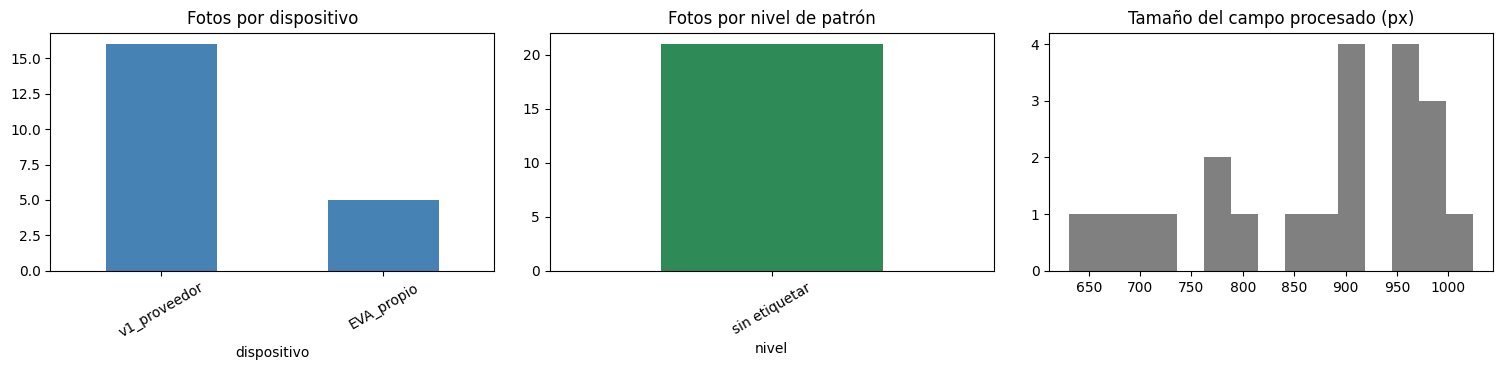

In [11]:
P = PROC.copy()
print("=== Etiquetas (nivel) ===")
print(P.nivel.value_counts(dropna=False).rename({0: "0 sin patrón", 1: "1 parcial", 2: "2 claro"}).to_string())
print("\n=== Dispositivo x nivel ===")
print(pd.crosstab(P.dispositivo, P.nivel.fillna(-1).map({-1: "sin etiquetar", 0: "0", 1: "1", 2: "2"})).to_string())
print("\n=== Split x label (solo fotos con label 0/1) ===")
print(pd.crosstab(P.split, P.label).to_string() if P.label.notna().any() else "(aún no hay fotos con nivel 0 o 2)")

avisos = []
n_sin = int(P.nivel.isna().sum())
if n_sin:
    avisos.append(f"{n_sin} foto(s) usadas todavía no tienen 'nivel': complétalo en el manifiesto (Paso 3).")
lab = P.label.dropna()
if len(lab) and lab.value_counts().min() < 30:
    avisos.append(f"La clase minoritaria tiene solo {int(lab.value_counts().min())} fotos (se recomiendan >= 30 para interpretar métricas).")
if len(lab) and P[P.split == "test"].label.dropna().nunique() < 2:
    avisos.append("El test no contiene ambas clases: no se podrá evaluar. Se necesitan más fotos/grupos o revisar la asignación.")
tab = pd.crosstab(P.dispositivo, P.label)
if tab.shape[0] > 1 and tab.shape[1] == 2:
    prop = tab[1] / tab.sum(axis=1)
    if prop.max() - prop.min() > 0.4:
        avisos.append("La proporción de helechos difiere mucho entre dispositivos (" +
                      ", ".join(f"{d}: {p:.0%}" for d, p in prop.items()) +
                      "). El modelo podría aprender el dispositivo en vez del patrón.")
print("\n=== Advertencias ===")
print("\n".join("⚠️ " + a for a in avisos) if avisos else "Sin advertencias graves.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
P.dispositivo.value_counts().plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Fotos por dispositivo")
P.nivel.fillna(-1).map({-1: "sin etiquetar", 0: "0 sin patrón", 1: "1 parcial", 2: "2 claro"}).value_counts().plot.bar(ax=ax[1], color="seagreen")
ax[1].set_title("Fotos por nivel de patrón")
ax[2].hist(P.lado_procesado, bins=15, color="gray"); ax[2].set_title("Tamaño del campo procesado (px)")
for a in ax[:2]:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## Cierre · Qué guardar y cómo documentarlo — *para el informe y la postulación*

**Archivos generados (carpeta `dataset_eva/`):**
- `manifiesto.csv`: planilla maestra, con nombres originales. **Privada.**
- `manifiesto_procesado.csv` + `imgs/`: lo que usa el Notebook 2. No contiene nombres originales.

**Criterios de inclusión/exclusión (anótalos tal cual en tu informe):**
1. Se excluyen fotos donde no se identifica el campo del microscopio, o con campo menor a `MIN_LADO_PX` px.
2. Se excluyen duplicados exactos.
3. Se excluyen manualmente (`incluir=0`) las fotos con motivo documentado (ej. foto del ocular con la mano, sin muestra, desenfoque severo).
4. **No** se excluyen fotos por "dificultad" del patrón: los casos dudosos se etiquetan como nivel 1.
5. Las fotos se recortan al campo y se reducen (nunca se amplían) a un máximo de `MAX_LADO_MASTER` px.

**Cuando lleguen fotos nuevas:** ponlas en `fotos_crudas/` y ejecuta de nuevo desde el Paso 1. Los IDs, las etiquetas y el test congelado se mantienen.

**Siguiente paso:** abre el **Notebook 2** (`EVA_02_Entrenamiento_Evaluacion.ipynb`).